## A. Preparar el entorno

Archivos necesarios (todos vienen dentro de `PAQUETE_DEMO_COLAB.zip`):

| Archivo | Para qué sirve |
|---|---|
| `mejor_pipeline_supervisado.joblib` | El modelo entrenado (pipeline completo: preprocesamiento + SVM + calibración) |
| `ml_utils.py`, `v2_utils.py` | Código del proyecto que define clases propias usadas dentro del pipeline (`MultiEtiquetaBinarizer`, `MapeoOrdinal`, `FiltroCorrelacion`). **Sin ellos el `.joblib` no se puede cargar.** |
| `mejor_pipeline_supervisado_metadatos.json` | Métricas, hiperparámetros y advertencias guardadas junto al modelo |
| `dataset_relaciones_musica.csv` | Los 20 participantes anonimizados (formato que espera el modelo) |
| `predicciones_fuera_de_muestra_svm_dummy.csv` | Predicciones de la validación cruzada ya guardadas (para el *score honesto*) |
| `comparacion_final_anterior_nuevo_dummy.csv` | Métricas documentadas de V1, V2 y Dummy |
| `ejemplo_sintetico.csv` | 2 personas **inventadas** para probar la carga de un CSV |

**Celda 1:** detecta si estamos en Colab o en Jupyter local y muestra las versiones.

In [1]:
import sys, importlib, platform

EN_COLAB = False

print("Entorno :", "Google Colab" if EN_COLAB else "Jupyter local")
print("Python  :", sys.version.split()[0], "|", platform.platform())
for lib in ["sklearn", "joblib", "numpy", "pandas", "scipy", "matplotlib"]:
    try:
        print(f"{lib:11s}:", importlib.import_module(lib).__version__)
    except ImportError:
        print(f"{lib:11s}: NO INSTALADO")

Entorno : Jupyter local
Python  : 3.14.0 | Windows-10-10.0.19045-SP0
sklearn    : 1.9.1
joblib     : 1.6.0
numpy      : 2.5.4
pandas     : 3.1.1
scipy      : 1.18.1
matplotlib : 3.11.2


**Celda 2: compatibilidad del `.joblib`.** Un `.joblib` guarda objetos de Python con *pickle*; los objetos de
scikit-learn solo están garantizados con **la misma versión** con la que se guardaron (**scikit-learn 1.9.1**).
Si la versión es otra, en Colab se instala la correcta y **hay que reiniciar la sesión**
(*Entorno de ejecución → Reiniciar sesión*) y volver a ejecutar desde la celda 1.

In [2]:
import sklearn

VERSIONES_DEL_ENTRENAMIENTO = {"scikit-learn": "1.9.1", "joblib": "1.6.0", "numpy": "2.5.5",
                               "pandas": "3.1.1", "scipy": "1.18.1", "python": "3.14"}
print("Versiones con las que se guardó el modelo:", VERSIONES_DEL_ENTRENAMIENTO)

if sklearn.__version__ == "1.9.1":
    print("OK: scikit-learn 1.9.1, la misma versión del entrenamiento.")
elif EN_COLAB:
    import subprocess
    print(f"scikit-learn {sklearn.__version__} != 1.9.1 -> instalando la versión correcta (requiere Python >= 3.11)...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.9.1", "joblib==1.6.0"], check=True)
    print("\n>>> INSTALADO. Ahora: menú 'Entorno de ejecución' -> 'Reiniciar sesión' y vuelve a ejecutar desde la celda 1.")
    raise SystemExit("Reinicia la sesión antes de continuar.")
else:
    print(f"ATENCIÓN: scikit-learn {sklearn.__version__}. Instala la versión del entrenamiento con:\n"
          "    pip install scikit-learn==1.9.1 joblib==1.6.0\ny reinicia el kernel.")

Versiones con las que se guardó el modelo: {'scikit-learn': '1.9.1', 'joblib': '1.6.0', 'numpy': '2.5.5', 'pandas': '3.1.1', 'scipy': '1.18.1', 'python': '3.14'}
OK: scikit-learn 1.9.1, la misma versión del entrenamiento.


**Celda 3: localizar los archivos.** En Jupyter local se encuentran solos (carpeta `EXPOSICION/PAQUETE_DEMO_COLAB`).
En Colab, si aún no están, se abre el selector: elige **`PAQUETE_DEMO_COLAB.zip`**.

In [3]:
from pathlib import Path
import zipfile

NOMBRE_PAQUETE = "PAQUETE_DEMO_COLAB"

def buscar_paquete():
    aqui = Path.cwd().resolve()
    candidatos = [aqui / NOMBRE_PAQUETE, aqui]
    candidatos += [p / "EXPOSICION" / NOMBRE_PAQUETE for p in aqui.parents]
    candidatos += [Path("/content") / NOMBRE_PAQUETE, Path("/content")]
    for d in candidatos:
        if (d / "mejor_pipeline_supervisado.joblib").exists() and (d / "v2_utils.py").exists():
            return d
    return None

DEMO_DIR = buscar_paquete()

if DEMO_DIR is None:
    raise FileNotFoundError("No encuentro el paquete de la demo. En Colab sube PAQUETE_DEMO_COLAB.zip; en local "
                            "abre este notebook desde la carpeta del proyecto ENTREGA_FINAL_MODELOS.")
print("Archivos de la demo en:", DEMO_DIR)
for f in sorted(DEMO_DIR.iterdir()):
    print("   ", f.name)

Archivos de la demo en: C:\Users\ahang\OneDrive\Escritorio\Sistemas Inteligentes\LimpiezaData\notebooks\PAQUETE_DEMO_COLAB
    comparacion_final_anterior_nuevo_dummy.csv
    dataset_relaciones_musica.csv
    ejemplo_sintetico.csv
    mejor_pipeline_supervisado.joblib
    mejor_pipeline_supervisado_metadatos.json
    ml_utils.py
    predicciones_fuera_de_muestra_svm_dummy.csv
    v2_utils.py


**Celda 4: seguridad.** Cargar un `.joblib` **ejecuta código**, así que nunca se debe cargar uno de origen
desconocido. Antes de cargarlo comprobamos que su huella SHA-256 (y la de los módulos `.py`) coincide con la del
archivo original del proyecto. Si no coincide, el notebook se detiene.

In [4]:
import hashlib

HUELLAS_ESPERADAS = {
    "mejor_pipeline_supervisado.joblib": "1cd16a39ecce9fd54d6b214705108efa7c0ae0ad141a893fb30e508741a6e5c8",
    "ml_utils.py": "09ad3e2d0f19450aed8388befa9f169740d666a633865723da1deb084fa7c163",
    "v2_utils.py": "6bbec87598d9a212498c66e6891593301bb16df08a913bafb5f83f119296a0aa"
}
HUELLAS_DATOS = {
    "comparacion_final_anterior_nuevo_dummy.csv": "e76e52afc1aa0f503923f4d0eb9a7af5f97513149e669acdaeb8edfe384f9b60",
    "dataset_relaciones_musica.csv": "b3495a851ead1be354d634c4469df3d8784599fcefbe098b99df25f2dad1c83b",
    "predicciones_fuera_de_muestra_svm_dummy.csv": "58c9c74c2e8aa0a250f8a76944d2957e2e39b36c92b8aad6a0cad938ca295589"
}

def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

for nombre, esperado in {**HUELLAS_ESPERADAS, **HUELLAS_DATOS}.items():
    ok = sha256(DEMO_DIR / nombre) == esperado
    print(("OK      " if ok else "DISTINTO"), nombre)
    if not ok and nombre in HUELLAS_ESPERADAS:
        raise RuntimeError(f"{nombre} NO es el archivo original: no se carga (podría ejecutar código ajeno).")
print("\nEl modelo y los módulos son idénticos a los originales del proyecto.")

OK       mejor_pipeline_supervisado.joblib
OK       ml_utils.py
OK       v2_utils.py
OK       comparacion_final_anterior_nuevo_dummy.csv
OK       dataset_relaciones_musica.csv
OK       predicciones_fuera_de_muestra_svm_dummy.csv

El modelo y los módulos son idénticos a los originales del proyecto.


## B. Cargar el modelo

El `.joblib` contiene un **diccionario** con tres claves:
`pipeline` (el modelo), `variables_entrada` (las 37 columnas que espera) y `metadatos`.
El pipeline usa clases propias del proyecto, por eso primero añadimos la carpeta de los módulos a `sys.path`.
El archivo **solo se lee**: no se modifica ni se vuelve a guardar.

In [5]:
import json, warnings
import joblib
import numpy as np
import pandas as pd

if str(DEMO_DIR) not in sys.path:
    sys.path.insert(0, str(DEMO_DIR))       # para que pickle encuentre ml_utils y v2_utils

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    paquete = joblib.load(DEMO_DIR / "mejor_pipeline_supervisado.joblib")
for a in avisos:
    if "Version" in type(a.message).__name__:
        print("AVISO de versión:", a.message)

modelo = paquete["pipeline"]
VARIABLES = paquete["variables_entrada"]
META = paquete["metadatos"]
print(type(modelo).__name__, "con", len(modelo.steps), "pasos y", len(VARIABLES), "variables de entrada\n")
for nombre, paso in modelo.steps:
    print(f"  {nombre:12s} -> {type(paso).__name__}")
print("\nHiperparámetros finales:", META["hiperparametros_finales"])
print("Advertencia guardada  :", META["advertencia"])

Pipeline con 5 pasos y 37 variables de entrada

  prep         -> ColumnTransformer
  varianza     -> VarianceThreshold
  redundancia  -> FiltroCorrelacion
  escalar      -> StandardScaler
  modelo       -> CalibratedClassifierCV

Hiperparámetros finales: {'modelo__estimator__C': '10.0', 'modelo__estimator__gamma': 'scale'}
Advertencia guardada  : NO SUPERA AL DUMMY DE FORMA FIABLE: resultado exploratorio con 20 participantes (cumple los criterios pre-registrados, pero la prueba corregida por seleccion no es significativa). Uso exclusivamente academico; no usar para tomar decisiones sobre personas.


**Orden real de las clases.** `predict_proba` devuelve una columna por clase en el orden de `classes_`.
Lo comprobamos en lugar de suponerlo.

In [6]:
print("modelo.classes_ =", modelo.classes_)
COL = {int(clase): i for i, clase in enumerate(modelo.classes_)}
ETIQUETA = {0: "No tiene pareja", 1: "Tiene pareja"}
assert set(COL) == {0, 1}
print(f"Columna {COL[0]} de predict_proba = P(no tiene pareja);  columna {COL[1]} = P(tiene pareja)")

modelo.classes_ = [0 1]
Columna 0 de predict_proba = P(no tiene pareja);  columna 1 = P(tiene pareja)


**Dentro del modelo.** El último paso es `CalibratedClassifierCV`, que contiene el `SVC` (kernel RBF) y el
calibrador sigmoide (Platt). Mostramos los valores **reales** aprendidos.

In [7]:
cal = modelo.named_steps["modelo"]
svc = cal.calibrated_classifiers_[0].estimator
platt = cal.calibrated_classifiers_[0].calibrators[0]
n_caracteristicas = modelo.named_steps["escalar"].n_features_in_

print("Kernel                       :", svc.kernel)
print("C                            :", svc.C)
print("gamma (configurado)          :", svc.gamma, "-> valor efectivo", round(svc._gamma, 5),
      f"(= 1 / ({n_caracteristicas} características x varianza 1 tras estandarizar))")
print("class_weight                 :", svc.class_weight)
print("Características que ve el SVM:", n_caracteristicas)
print("Vectores de soporte por clase:", dict(zip(["no (0)", "sí (1)"], svc.n_support_.tolist())),
      "-> total", svc.n_support_.sum(), "de 20 personas")
print(f"Calibración sigmoide (Platt) : P(sí) = 1 / (1 + exp(a·f + b)),  a = {platt.a_:.3f},  b = {platt.b_:.3f}")
print("  a > 0 significa que la calibración INVIERTE la puntuación f del SVM (ver sección E.3).")

Kernel                       : rbf
C                            : 10.0
gamma (configurado)          : scale -> valor efectivo 0.01111 (= 1 / (90 características x varianza 1 tras estandarizar))
class_weight                 : balanced
Características que ve el SVM: 90
Vectores de soporte por clase: {'no (0)': 11, 'sí (1)': 9} -> total 20 de 20 personas
Calibración sigmoide (Platt) : P(sí) = 1 / (1 + exp(a·f + b)),  a = 10.721,  b = 1.294
  a > 0 significa que la calibración INVIERTE la puntuación f del SVM (ver sección E.3).


## C. Cargar los datos

El modelo recibe las **37 variables originales** (las del CSV derivado), **no** las 90 características ya
transformadas: el propio pipeline imputa, codifica y escala. Las columnas extra (`id_anonimo`, `tiene_pareja`,
`nunca_tuvo_relacion`) se ignoran para predecir.

La tabla siguiente se genera **a partir del propio pipeline** y dice qué valores entiende cada columna.

In [8]:
from v2_utils import MAPAS_ORDINALES

prep = modelo.named_steps["prep"]
filas = []
for nombre, trans, cols in prep.transformers_:
    if nombre == "remainder":
        continue
    for col in cols:
        if nombre == "num":
            valores = "número (vacío -> mediana)"
        elif nombre == "bin":
            valores = "0 / 1 (vacío -> valor más frecuente)"
        elif nombre == "ord":
            valores = " | ".join(MAPAS_ORDINALES[col]) + "  (otro/'indeterminado' -> mediana)"
        elif nombre == "cat":
            valores = " | ".join(trans.named_steps["ohe"].categories_[0]) + "  (raras se agrupan)"
        else:
            valores = "etiquetas separadas por coma: " + (", ".join(trans.vocabulario_[col]) or "(ninguna frecuente)")
        filas.append({"columna": col, "tipo": nombre, "valores que usa el modelo": valores})
pd.set_option("display.max_colwidth", 120)
formato = pd.DataFrame(filas)
formato

,columna,tipo,valores que usa el modelo
0,edad_primera_relacion_val,num,número (vacío -> mediana)
1,diferencia_edad_max_val,num,número (vacío -> mediana)
2,mus_horas_dia,num,número (vacío -> mediana)
3,mus_n_plataformas,num,número (vacío -> mediana)
4,diferencia_edad_indefinida,bin,0 / 1 (vacío -> valor más frecuente)
5,mus_escucha_musica,bin,0 / 1 (vacío -> valor más frecuente)
6,mus_tuvo_experiencia,bin,0 / 1 (vacío -> valor más frecuente)
7,mus_usa_spotify,bin,0 / 1 (vacío -> valor más frecuente)
8,mus_usa_youtube,bin,0 / 1 (vacío -> valor más frecuente)
9,mus_usa_youtube_music,bin,0 / 1 (vacío -> valor más frecuente)


**Elegir el CSV.**
* Por defecto se usa `dataset_relaciones_musica.csv` (los 20 participantes del proyecto).
* **Jupyter local:** escribe la ruta en `RUTA_CSV`, por ejemplo `RUTA_CSV = "../../EXPOSICION/PAQUETE_DEMO_COLAB/ejemplo_sintetico.csv"`.
* **Colab:** pon `USAR_SELECTOR_COLAB = True` y elige el archivo en la ventana que aparece
  (por ejemplo `ejemplo_sintetico.csv`).

In [ ]:
RUTA_CSV = None               # Jupyter local: ruta a tu CSV (None = dataset del proyecto)
USAR_SELECTOR_COLAB = False   # Colab: True para elegir un CSV con el selector de archivos

if RUTA_CSV is None:
    RUTA_CSV = DEMO_DIR / "dataset_relaciones_musica.csv"

datos = pd.read_csv(RUTA_CSV)
print("CSV:", RUTA_CSV, "->", datos.shape[0], "filas,", datos.shape[1], "columnas")

faltan = [c for c in VARIABLES if c not in datos.columns]
if faltan:
    raise ValueError(f"Al CSV le faltan {len(faltan)} columnas que el modelo necesita: {faltan}")

X = datos[VARIABLES].copy()
TIPO = dict(zip(formato.columna, formato.tipo))
for col in VARIABLES:                                  # números: texto no numérico -> vacío
    if TIPO[col] in ("num", "bin"):
        X[col] = pd.to_numeric(X[col], errors="coerce")

# Avisos (no errores): valores que el modelo no conoce y que acabará tratando como faltantes / ignorando
ignoradas = {}
for nombre, trans, cols in prep.transformers_:
    for col in (cols if nombre in ("ord", "multi") else []):
        if nombre == "ord":
            raros = set(X[col].dropna()) - set(MAPAS_ORDINALES[col]) - {"indeterminado"}
        else:
            toks = {t.strip().lower() for v in X[col].dropna() for t in str(v).split(",") if t.strip()}
            raros = toks - set(trans.vocabulario_[col])
        if raros and nombre == "ord":
            print(f"Aviso: {col} tiene valores no previstos {sorted(raros)} -> se imputan con la mediana")
        elif raros:
            ignoradas[col] = len(raros)
if ignoradas:
    print(f"Nota: en {len(ignoradas)} preguntas de respuesta múltiple hay etiquetas que el modelo ignora "
          f"({sum(ignoradas.values())} en total). Es normal: solo usa etiquetas que aparecieron >= 3 veces al entrenar.")

IDS = datos["id_anonimo"] if "id_anonimo" in datos else pd.Series([f"fila_{i+1}" for i in range(len(datos))])
TIENE_OBJETIVO = "tiene_pareja" in datos.columns and datos["tiene_pareja"].notna().all()
print("\n¿El CSV trae la respuesta verdadera 'tiene_pareja'?", "Sí" if TIENE_OBJETIVO else "No")
X.head()

CSV: C:\Users\ahang\OneDrive\Escritorio\Sistemas Inteligentes\LimpiezaData\notebooks\PAQUETE_DEMO_COLAB\dataset_relaciones_musica.csv -> 20 filas, 40 columnas
Nota: en 17 preguntas de respuesta múltiple hay etiquetas que el modelo ignora (84 en total). Es normal: solo usa etiquetas que aparecieron >= 3 veces al entrenar.

¿El CSV trae la respuesta verdadera 'tiene_pareja'? Sí


,edad_primera_relacion_val,diferencia_edad_max_val,mus_horas_dia,mus_n_plataformas,diferencia_edad_indefinida,mus_escucha_musica,mus_tuvo_experiencia,mus_usa_spotify,mus_usa_youtube,mus_usa_youtube_music,...,cita_ideal_cat,mus_generos_frecuentes,mus_razon_genero,mus_generos_emocion,mus_generos_animo_negativo,mus_estrategia_animo_negativo,mus_actividades,mus_experiencia_conceptos,mus_caracteristicas,mus_mecanismos_ayuda
0,14.0,2.0,0.0,0,0,0.0,0.0,0,0,0,...,Aventura / Viaje,NaN,NaN,NaN,NaN,no usa musica,NaN,NaN,"volumen, idioma",NaN
1,12.0,4.0,7.0,1,0,1.0,1.0,1,0,0,...,"Gastronomía / Comida, Aire libre / Naturaleza, Entretenimiento / Cultura",regional mexicano,"ritmo, gusto/favorito",regional mexicano,"regional mexicano, baladas",NaN,"trayectos/transporte, ejercicio, videojuegos",motivacion/energia,"ritmo, letra",desahogo/identificacion
2,15.0,3.0,9.0,1,0,1.0,1.0,0,0,1,...,"Privacidad, Espontaneidad / Imprevisto","rock, alternativo/indie",NaN,"pop, rock, hip-hop/rap, clasica",soundtrack/instrumental,relajarse,"tareas/estudio, relajacion/descanso, todo el dia",nostalgia,ritmo,NaN
3,12.0,2.0,8.0,1,0,1.0,1.0,1,0,0,...,Otro / No clasificado,pop,NaN,pop,clasica,relajarse,todo el dia,contexto negativo previo,ritmo,cambia el animo
4,13.0,4.0,4.0,1,0,1.0,1.0,1,0,0,...,Gastronomía / Comida,"r&b, alternativo/indie",novedad/diversidad,"pop, r&b, reggaeton/urbano, alternativo/indie",reggaeton/urbano,distraerse/animarse,trayectos/transporte,"relajacion/calma, contexto negativo previo",ritmo,activacion/motivacion


## D. Realizar predicciones

* `modelo.predict(X)` devuelve 0 o 1.
* `modelo.predict_proba(X)` devuelve la probabilidad de cada clase (en el orden de `classes_`).

> Con 20 personas, las probabilidades son **inestables**: la calibración se ajustó con muy pocas personas y su
> pendiente es muy pronunciada, por eso suelen salir valores extremos (cercanos a 0 o a 1). No deben leerse como
> "seguridad" del modelo.

In [10]:
pred = modelo.predict(X)
proba = modelo.predict_proba(X)

tabla = pd.DataFrame({
    "participante": IDS.values,
    "predicción": [ETIQUETA[int(p)] for p in pred],
    "P(no tiene pareja)": proba[:, COL[0]].round(3),
    "P(tiene pareja)": proba[:, COL[1]].round(3),
})
if TIENE_OBJETIVO:
    tabla["valor real"] = [ETIQUETA[int(v)] for v in datos["tiene_pareja"]]
    tabla["¿acierta?"] = np.where(pred == datos["tiene_pareja"].astype(int).values, "sí", "no")
assert (pred == modelo.classes_[proba.argmax(axis=1)]).all()   # predict es coherente con predict_proba
tabla

,participante,predicción,P(no tiene pareja),P(tiene pareja),valor real,¿acierta?
0,PRT01,No tiene pareja,1.0,0.0,Tiene pareja,no
1,PRT02,Tiene pareja,0.0,1.0,No tiene pareja,no
2,PRT03,No tiene pareja,1.0,0.0,Tiene pareja,no
3,PRT04,Tiene pareja,0.0,1.0,No tiene pareja,no
4,PRT05,No tiene pareja,1.0,0.0,Tiene pareja,no
5,PRT06,Tiene pareja,0.0,1.0,No tiene pareja,no
6,PRT07,Tiene pareja,0.0,1.0,No tiene pareja,no
7,PRT08,Tiene pareja,0.0,1.0,No tiene pareja,no
8,PRT09,No tiene pareja,1.0,0.0,Tiene pareja,no
9,PRT10,Tiene pareja,0.0,1.0,No tiene pareja,no


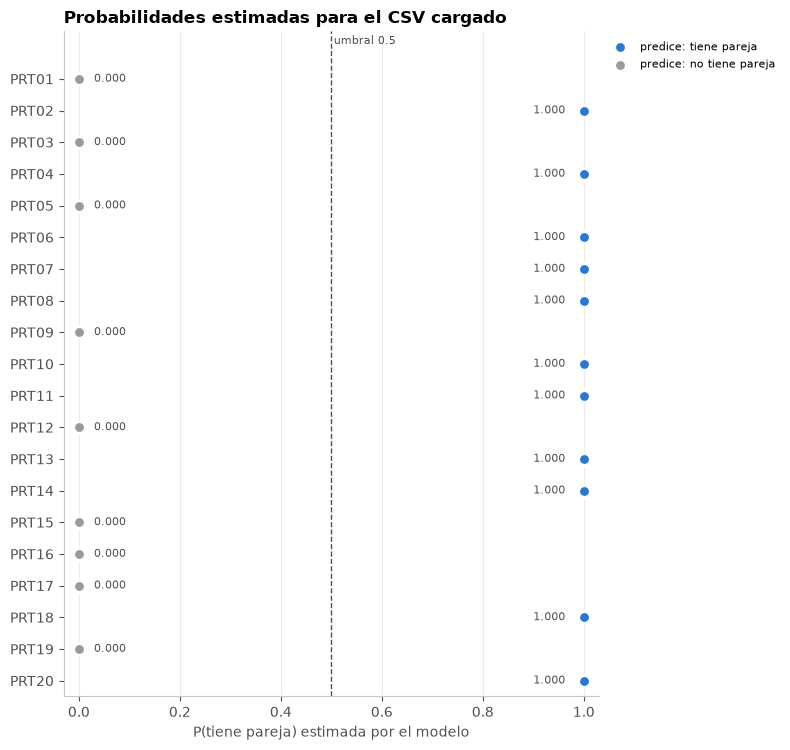

In [11]:
import matplotlib.pyplot as plt

AZUL, NARANJA, AQUA, GRIS, TINTA, TINTA2 = "#2a78d6", "#eb6834", "#1baf7a", "#9a9a96", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
                     "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10})

def grafica_probabilidades(ids, p_si, titulo):
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(ids) + 1.2))
    y_pos = np.arange(len(ids))
    p_si = np.asarray(p_si)
    for mascara, color, nombre in [(p_si > 0.5, AZUL, "predice: tiene pareja"),
                                   (p_si <= 0.5, GRIS, "predice: no tiene pareja")]:
        ax.scatter(p_si[mascara], y_pos[mascara], s=70, color=color, edgecolor="white", linewidth=2,
                   label=nombre, zorder=3)
    for yi, p in zip(y_pos, p_si):
        ax.text(min(p + 0.03, 0.9), yi, f"{p:.3f}", va="center", fontsize=8, color=TINTA2)
    ax.axvline(0.5, color=TINTA2, lw=1, ls="--")
    ax.set_yticks(y_pos, list(map(str, ids)))
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(len(ids) - 0.5, -1.5)
    ax.text(0.505, -1.1, "umbral 0.5", color=TINTA2, fontsize=8)
    ax.set_xlabel("P(tiene pareja) estimada por el modelo")
    ax.set_title(titulo, loc="left")
    ax.grid(axis="x", color="#ecebe6", lw=0.8)
    ax.set_axisbelow(True)
    ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False, fontsize=8)
    plt.tight_layout()
    plt.show()

grafica_probabilidades(IDS.values, proba[:, COL[1]], "Probabilidades estimadas para el CSV cargado")

## E. Calcular el score

### E.1 Score honesto: validación cruzada anidada (resultados guardados, sin reentrenar)

Este es el número que se defiende. Durante el proyecto, cada persona fue predicha **10 veces** (una por
repetición) por un modelo que **no la había visto** al entrenar. Esas 200 predicciones están guardadas;
aquí solo se recalculan las métricas con las funciones del propio proyecto
(`ml_utils.calcular_metricas` y `v2_utils.metricas_rep`).

In [12]:
from ml_utils import calcular_metricas
from v2_utils import metricas_rep

oof = pd.read_csv(DEMO_DIR / "predicciones_fuera_de_muestra_svm_dummy.csv")

def metricas_cv(nombre_modelo):
    d = oof[oof.modelo == nombre_modelo].sort_values(["repeticion", "id_anonimo"])
    probas = d.pivot(index="repeticion", columns="id_anonimo", values="proba_si").to_numpy()
    pliegue = d.pivot(index="repeticion", columns="id_anonimo", values="particion").to_numpy()
    y_real = d[d.repeticion == 0].sort_values("id_anonimo").y_real.to_numpy()
    return metricas_rep(y_real, probas, pliegue), d

rep_svm, oof_svm = metricas_cv("SVM RBF")
rep_dummy, oof_dummy = metricas_cv("Dummy (prior)")
cols_m = ["accuracy", "balanced_accuracy", "precision", "recall", "f1_macro", "roc_auc_por_particion", "brier"]
resumen_cv = pd.DataFrame({
    "SVM RBF (media)": rep_svm[cols_m].mean(), "SVM RBF (desv.)": rep_svm[cols_m].std(),
    "Dummy (media)": rep_dummy[cols_m].mean()}).round(4)
print("Promedio de 10 repeticiones de CV anidada 5 x 10 (cada repetición = 20 predicciones fuera de muestra)")
display(resumen_cv)

doc = META["metricas_cv_anidada_media"]
for m in cols_m:
    assert abs(rep_svm[m].mean() - doc[m]) < 1e-3, m
print("Coinciden con las métricas documentadas en los metadatos del modelo (accuracy 0.715, BA 0.7066, ...).")

Promedio de 10 repeticiones de CV anidada 5 x 10 (cada repetición = 20 predicciones fuera de muestra)


,SVM RBF (media),SVM RBF (desv.),Dummy (media)
accuracy,0.7150,0.0973,0.5500
balanced_accuracy,0.7066,0.0964,0.5000
precision,0.7290,0.1596,0.0000
recall,0.6222,0.1194,0.0000
f1_macro,0.7066,0.0980,0.3548
roc_auc_por_particion,0.8550,0.1080,0.5000
brier,0.1831,0.0241,0.2531


Coinciden con las métricas documentadas en los metadatos del modelo (accuracy 0.715, BA 0.7066, ...).


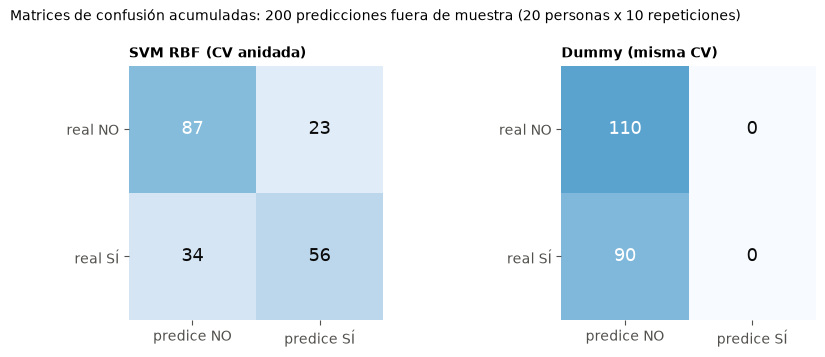

In [13]:
from sklearn.metrics import confusion_matrix

def dibujar_matriz(ax, cm, titulo):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=cm.sum())
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="white" if cm[i, j] > cm.sum() * 0.35 else TINTA)
    ax.set_xticks([0, 1], ["predice NO", "predice SÍ"])
    ax.set_yticks([0, 1], ["real NO", "real SÍ"])
    ax.set_title(titulo, loc="left", fontsize=10)
    for s in ax.spines.values():
        s.set_visible(False)

fig, axs = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, d, t in [(axs[0], oof_svm, "SVM RBF (CV anidada)"), (axs[1], oof_dummy, "Dummy (misma CV)")]:
    cm = confusion_matrix(d.y_real, (d.proba_si > 0.5).astype(int), labels=[0, 1])
    dibujar_matriz(ax, cm, t)
fig.suptitle("Matrices de confusión acumuladas: 200 predicciones fuera de muestra (20 personas x 10 repeticiones)",
             fontsize=10, x=0.01, ha="left")
plt.tight_layout()
plt.show()

### E.2 Score sobre el CSV cargado

Si el CSV trae `tiene_pareja`, se calculan todas las métricas. Si **son los mismos 20 participantes con los que
se ajustó el modelo final**, el resultado **no** es una evaluación independiente y **no** debe presentarse como
rendimiento con datos nuevos (la celda lo detecta y avisa).

*** ATENCIÓN: 20 de 20 filas son participantes con los que se AJUSTÓ el modelo final. ***
*** Esto NO es una evaluación independiente. El score honesto es el de la sección E.1. ***

accuracy                0.0
balanced_accuracy       0.0
precision (clase sí)    0.0
recall (clase sí)       0.0
f1 (clase sí)           0.0
f1_macro                0.0
roc_auc                 0.0

                 precision    recall  f1-score   support

no tiene pareja       0.00      0.00      0.00      11.0
   tiene pareja       0.00      0.00      0.00       9.0

       accuracy                           0.00      20.0
      macro avg       0.00      0.00      0.00      20.0
   weighted avg       0.00      0.00      0.00      20.0



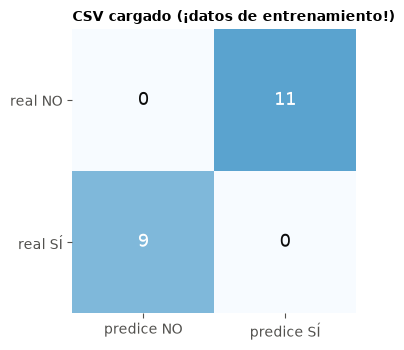

In [14]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report, f1_score,
                             precision_score, recall_score, roc_auc_score)

if not TIENE_OBJETIVO:
    print("El CSV no trae 'tiene_pareja': solo se pueden mostrar predicciones y probabilidades (sección D).")
else:
    y_csv = datos["tiene_pareja"].astype(int).to_numpy()
    entrenamiento = pd.read_csv(DEMO_DIR / "dataset_relaciones_musica.csv")
    def huella_fila(df):   # una cadena por persona con sus 37 respuestas (vacío = sin respuesta)
        return df[VARIABLES].apply(lambda col: col.map(lambda v: "" if pd.isna(v) else str(v))).agg("|".join, axis=1)
    repetidas = huella_fila(datos).isin(set(huella_fila(entrenamiento))).sum()
    if repetidas:
        print(f"*** ATENCIÓN: {repetidas} de {len(datos)} filas son participantes con los que se AJUSTÓ el modelo final. ***")
        print("*** Esto NO es una evaluación independiente. El score honesto es el de la sección E.1. ***\n")
    p_si = proba[:, COL[1]]
    res = {"accuracy": accuracy_score(y_csv, pred),
           "balanced_accuracy": balanced_accuracy_score(y_csv, pred),
           "precision (clase sí)": precision_score(y_csv, pred, zero_division=0),
           "recall (clase sí)": recall_score(y_csv, pred, zero_division=0),
           "f1 (clase sí)": f1_score(y_csv, pred, zero_division=0),
           "f1_macro": f1_score(y_csv, pred, average="macro", zero_division=0),
           "roc_auc": roc_auc_score(y_csv, p_si) if len(set(y_csv)) == 2 else float("nan")}
    print(pd.Series(res).round(4).to_string())
    print("\n" + classification_report(y_csv, pred, labels=[0, 1], target_names=["no tiene pareja", "tiene pareja"],
                                       zero_division=0))
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    dibujar_matriz(ax, confusion_matrix(y_csv, pred, labels=[0, 1]),
                   "CSV cargado" + (" (¡datos de entrenamiento!)" if repetidas else ""))
    plt.tight_layout()
    plt.show()

### E.3 ¿Por qué con los 20 participantes del entrenamiento sale un score tan malo?

Con el dataset del proyecto, el modelo final **acierta 0 de 20**. No es un error de la demo; es la explicación
del "patrón invertido" descrito en el informe técnico (sección 5):

1. El `SVC` con C = 10 y 90 características **memoriza** a las 20 personas (las 20 son vectores de soporte): su
   puntuación `f` vale ≈ +1 para quien tiene pareja y ≈ −1 para quien no.
2. La calibración sigmoide se ajustó con **validación cruzada interna** (`cv=3`): con personas que el SVM **no**
   había visto, la puntuación salía **al revés** (en estos datos, cada persona se parece más a las de la clase
   contraria). Por eso aprendió una pendiente `a > 0`, que **voltea** la puntuación.
3. Al aplicar ese volteo a personas que el SVM sí memorizó, todas quedan mal.

Con personas **nuevas** el modelo usa el volteo como se diseñó; ese es el escenario que estima la CV anidada
(sección E.1: 71.5 %). Esto demuestra en vivo por qué **nunca** se evalúa un modelo con sus datos de entrenamiento.

In [15]:
entrenamiento = pd.read_csv(DEMO_DIR / "dataset_relaciones_musica.csv")
Z = modelo[:-1].transform(entrenamiento[VARIABLES])        # las 90 características que ve el SVM
f = svc.decision_function(Z)                               # puntuación del SVM (sin calibrar)
p_manual = 1 / (1 + np.exp(platt.a_ * f + platt.b_))       # fórmula de Platt
p_modelo = modelo.predict_proba(entrenamiento[VARIABLES])[:, COL[1]]
assert np.allclose(p_manual, p_modelo)

demo = pd.DataFrame({"participante": entrenamiento.id_anonimo, "real": entrenamiento.tiene_pareja,
                     "f del SVM": f.round(3), "SVM solo predice": (f > 0).astype(int),
                     "P(sí) calibrada": p_modelo.round(4), "modelo final predice": (p_modelo > 0.5).astype(int)})
print("SVM sin calibrar, con datos que memorizó: acierta",
      (demo["SVM solo predice"] == demo.real).sum(), "de 20")
print("Tras la calibración (volteo):             acierta",
      (demo["modelo final predice"] == demo.real).sum(), "de 20")
print("La fórmula manual de Platt reproduce exactamente predict_proba.")
demo.head(8)

SVM sin calibrar, con datos que memorizó: acierta 20 de 20
Tras la calibración (volteo):             acierta 0 de 20
La fórmula manual de Platt reproduce exactamente predict_proba.


,participante,real,f del SVM,SVM solo predice,P(sí) calibrada,modelo final predice
0,PRT01,1,1.0,1,0.0000,0
1,PRT02,0,-1.0,0,0.9999,1
2,PRT03,1,1.0,1,0.0000,0
3,PRT04,0,-1.0,0,0.9999,1
4,PRT05,1,1.0,1,0.0000,0
5,PRT06,0,-1.0,0,0.9999,1
6,PRT07,0,-1.0,0,0.9999,1
7,PRT08,0,-1.0,0,0.9999,1


## F. Visualizaciones: V1, V2 y Dummy (métricas documentadas)

Todas son medias de la misma validación cruzada anidada (mismas particiones), leídas de
`comparacion_final_anterior_nuevo_dummy.csv`. Nada se recalcula.

,accuracy,balanced_accuracy,f1_macro,roc_auc_por_particion,brier
Mejor V1 (Música · árbol),0.470,0.461,0.450,0.439,0.392
V1 oficial (Rel.+Mús. · árbol),0.405,0.396,0.389,0.404,0.438
V2: SVM RBF (Rel.+Mús.),0.715,0.707,0.707,0.855,0.183
Dummy,0.550,0.500,0.355,0.500,0.253


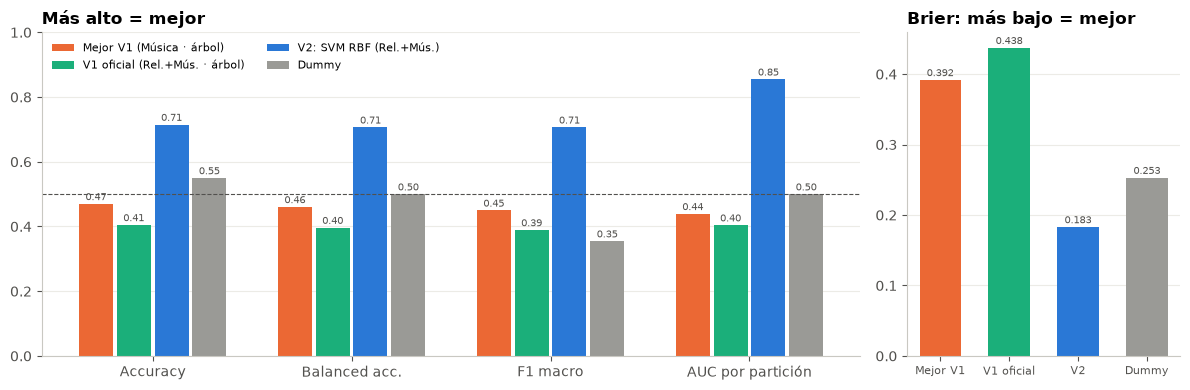

Recordatorio: p corregido por selección = 0.0891 -> la mejora frente al Dummy NO es estadísticamente concluyente.


In [16]:
comp = pd.read_csv(DEMO_DIR / "comparacion_final_anterior_nuevo_dummy.csv")
filas = {"Mejor V1 (Música · árbol)": comp.rol.str.startswith("Mejor modelo anterior"),
         "V1 oficial (Rel.+Mús. · árbol)": comp.rol.str.startswith("Modelo oficial V1"),
         "V2: SVM RBF (Rel.+Mús.)": comp.rol.str.startswith("Mejor modelo nuevo"),
         "Dummy": comp.rol.str.startswith("Dummy")}
tabla_comp = pd.DataFrame({k: comp[m].iloc[0] for k, m in filas.items()}).T
metricas_sup = ["accuracy", "balanced_accuracy", "f1_macro", "roc_auc_por_particion"]
tabla_comp = tabla_comp[metricas_sup + ["brier"]].astype(float)
display(tabla_comp.round(3))

colores = [NARANJA, AQUA, AZUL, GRIS]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
ancho = 0.19
x = np.arange(len(metricas_sup))
for i, (nombre, color) in enumerate(zip(tabla_comp.index, colores)):
    v = tabla_comp.loc[nombre, metricas_sup].to_numpy()
    barras = ax1.bar(x + (i - 1.5) * ancho, v, ancho * 0.9, color=color, label=nombre)
    ax1.bar_label(barras, fmt="%.2f", fontsize=7, color=TINTA2, padding=1)
ax1.axhline(0.5, color=TINTA2, lw=0.8, ls="--")
ax1.set_xticks(x, ["Accuracy", "Balanced acc.", "F1 macro", "AUC por partición"])
ax1.set_ylim(0, 1)
ax1.set_title("Más alto = mejor", loc="left")
ax1.legend(frameon=False, fontsize=8, ncol=2, loc="upper left")
b = ax2.bar(range(4), tabla_comp["brier"], 0.6, color=colores)
ax2.bar_label(b, fmt="%.3f", fontsize=7, color=TINTA2, padding=1)
ax2.set_xticks(range(4), ["Mejor V1", "V1 oficial", "V2", "Dummy"], fontsize=8)
ax2.set_title("Brier: más bajo = mejor", loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", color="#ecebe6", lw=0.8)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()
print("Recordatorio: p corregido por selección =", META["p_valor_corregido_por_seleccion"],
      "-> la mejora frente al Dummy NO es estadísticamente concluyente.")

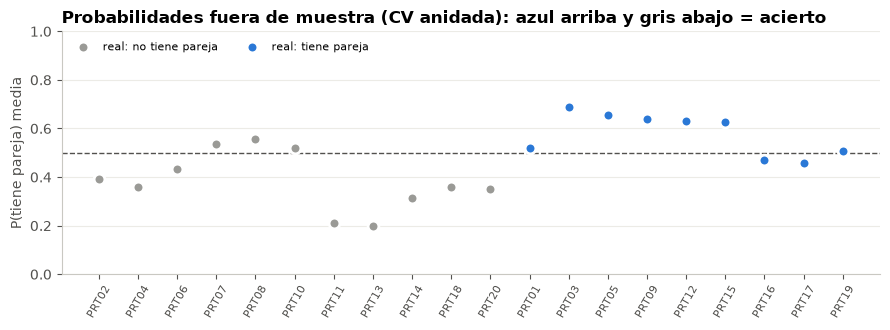

In [17]:
# Probabilidad media fuera de muestra de cada participante (10 repeticiones de la CV anidada)
media = oof_svm.groupby("id_anonimo").agg(real=("y_real", "first"), p=("proba_si", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(9, 3.4))
for clase, color, nombre in [(0, GRIS, "real: no tiene pareja"), (1, AZUL, "real: tiene pareja")]:
    d = media[media.real == clase]
    ax.scatter(d.id_anonimo, d.p, s=60, color=color, edgecolor="white", linewidth=2, label=nombre, zorder=3)
ax.axhline(0.5, color=TINTA2, lw=1, ls="--")
ax.set_ylim(0, 1)
ax.set_ylabel("P(tiene pareja) media")
ax.set_title("Probabilidades fuera de muestra (CV anidada): azul arriba y gris abajo = acierto", loc="left")
ax.tick_params(axis="x", rotation=60, labelsize=8)
ax.grid(axis="y", color="#ecebe6", lw=0.8)
ax.legend(frameon=False, fontsize=8, loc="upper left", ncol=2)
plt.tight_layout()
plt.show()

## G. Ejemplo práctico con datos SINTÉTICOS

Dos personas **inventadas** (no son participantes reales), escritas con las mismas columnas y categorías que
conoce el pipeline. También están en `ejemplo_sintetico.csv` para probar la carga de un CSV propio en la sección C.

,persona (SINTÉTICA),predicción,P(no tiene pareja),P(tiene pareja)
0,SINTETICO_01,Tiene pareja,0.017,0.983
1,SINTETICO_02,No tiene pareja,0.766,0.234


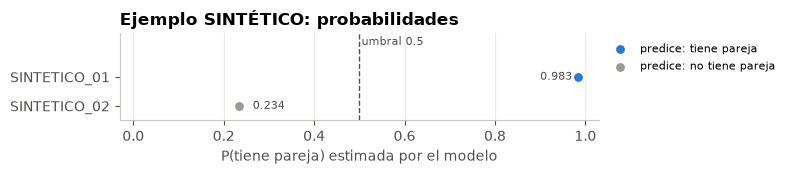

In [18]:
sinteticos = pd.DataFrame([
    {
        'id_anonimo': 'SINTETICO_01',
        'edad_primera_relacion_val': 15,
        'diferencia_edad_max_val': 3,
        'mus_horas_dia': 4,
        'mus_n_plataformas': 1,
        'diferencia_edad_indefinida': 0,
        'mus_escucha_musica': 1,
        'mus_tuvo_experiencia': 1,
        'mus_usa_spotify': 1,
        'mus_usa_youtube': 0,
        'mus_usa_youtube_music': 0,
        'mus_usa_apple_music': 0,
        'mus_importancia_nivel': 'alta',
        'mus_influencia_energia': 'alta',
        'mus_cambio_animo': 'mejora',
        'mus_ayuda_emociones': 'si',
        'mus_efecto_concentracion': 'ayuda',
        'mus_efecto_sueno': 'favorece',
        'mus_prefiere': 'prefiere musica',
        'diferencia_edad_dir': 'Cualquiera',
        'base_confianza': 'honestidad, comunicacion',
        'definicion_respeto': 'Trato digno',
        'cualidad_valorada': 'Conexión emocional',
        'no_negociables': 'infidelidad, mentiroso',
        'demostracion_carino': 'Tiempo de calidad, Apoyo emocional',
        'gesto_significativo': 'Presencia y compañía',
        'resolucion_desacuerdos': 'Comunicación directa',
        'pareja_ideal_fisico_cat': 'No relevante / Personalidad',
        'cita_ideal_cat': 'Gastronomía / Comida',
        'mus_generos_frecuentes': 'pop',
        'mus_razon_genero': 'ritmo',
        'mus_generos_emocion': 'pop, baladas',
        'mus_generos_animo_negativo': 'baladas',
        'mus_estrategia_animo_negativo': 'relajarse',
        'mus_actividades': 'tareas/estudio, trayectos/transporte',
        'mus_experiencia_conceptos': 'motivacion/energia',
        'mus_caracteristicas': 'ritmo, letra',
        'mus_mecanismos_ayuda': 'cambia el animo',
    },
    {
        'id_anonimo': 'SINTETICO_02',
        'edad_primera_relacion_val': 17,
        'diferencia_edad_max_val': 5,
        'mus_horas_dia': 1,
        'mus_n_plataformas': 2,
        'diferencia_edad_indefinida': 0,
        'mus_escucha_musica': 1,
        'mus_tuvo_experiencia': 0,
        'mus_usa_spotify': 0,
        'mus_usa_youtube': 1,
        'mus_usa_youtube_music': 1,
        'mus_usa_apple_music': 0,
        'mus_importancia_nivel': 'media',
        'mus_influencia_energia': 'media',
        'mus_cambio_animo': 'sin cambio',
        'mus_ayuda_emociones': 'condicional',
        'mus_efecto_concentracion': 'distrae',
        'mus_efecto_sueno': 'sin efecto',
        'mus_prefiere': 'prefiere silencio',
        'diferencia_edad_dir': 'Mayores',
        'base_confianza': 'lealtad, respeto',
        'definicion_respeto': 'Opinión y pensamiento',
        'cualidad_valorada': 'Valores éticos',
        'no_negociables': 'respeto',
        'demostracion_carino': 'Actos de servicio, Contacto físico',
        'gesto_significativo': 'Apoyo en momentos difíciles',
        'resolucion_desacuerdos': 'Empatía y comprensión',
        'pareja_ideal_fisico_cat': 'altura, cabello',
        'cita_ideal_cat': 'Aire libre / Naturaleza',
        'mus_generos_frecuentes': 'rock',
        'mus_razon_genero': 'gusto/favorito',
        'mus_generos_emocion': 'rock, hip-hop/rap',
        'mus_generos_animo_negativo': '',
        'mus_estrategia_animo_negativo': 'distraerse/animarse',
        'mus_actividades': 'ejercicio',
        'mus_experiencia_conceptos': '',
        'mus_caracteristicas': 'ritmo',
        'mus_mecanismos_ayuda': 'distraccion',
    },
])

sinteticos = sinteticos.replace("", np.nan)               # vacío = la persona no respondió
assert all(c in sinteticos.columns for c in VARIABLES)

p_sint = modelo.predict_proba(sinteticos[VARIABLES])
resultado = pd.DataFrame({
    "persona (SINTÉTICA)": sinteticos.id_anonimo,
    "predicción": [ETIQUETA[int(c)] for c in modelo.predict(sinteticos[VARIABLES])],
    "P(no tiene pareja)": p_sint[:, COL[0]].round(3),
    "P(tiene pareja)": p_sint[:, COL[1]].round(3),
})
display(resultado)
grafica_probabilidades(sinteticos.id_anonimo.values, p_sint[:, COL[1]], "Ejemplo SINTÉTICO: probabilidades")

## Conclusiones

* El pipeline completo (imputación → codificación → filtros → estandarización → SVM RBF → calibración sigmoide)
  está guardado en un solo archivo y se usa con `predict` / `predict_proba` sobre las respuestas originales.
* **Score honesto:** accuracy 0.715, balanced accuracy 0.707, F1 macro 0.707, AUC por partición 0.855,
  Brier 0.183 (media de CV anidada 5 × 10). El Dummy obtiene 0.55 / 0.50 / 0.355 / 0.50 / 0.253.
* La ventaja frente al Dummy **no es concluyente** (p = 0.0891 tras corregir por selección de modelos).
* El modelo se apoya en un patrón invertido ("cada persona se parece más a la clase contraria") que la
  calibración voltea; por eso evaluarlo con sus datos de entrenamiento da 0 %.
* La única forma de saber si funciona es **probarlo, sin reajustarlo, con participantes nuevos**.